# UJIAN TENGAH SEMESTER (UTS)
## Mata Kuliah Visualisasi Data — Program Studi Teknik Informatika

**Topik:** Visualisasi Data dengan Python (Pandas, Matplotlib, Seaborn)

| | |
|---|---|
| **Nama** | Moch. Rif'an Fatoni |
| **NIM** | 231101037 |
| **Kelas** | TI7B |

---

### Susunan notebook
Notebook disusun mengikuti urutan lima soal pada lembar UTS.

| Soal | Isi | Data |
|---|---|---|
| 1 | Konsep visualisasi dan pemilihan grafik | — |
| 2 | Bar chart Matplotlib | Angka pada lembar soal |
| 3 | Line chart tren penjualan | Angka pada lembar soal |
| 4 | DataFrame Pandas, scatter plot dan heatmap Seaborn | Data enam mahasiswa pada lembar soal |
| 5 | Studi kasus analisis data | Harga saham harian **BBCA.JK** (PT Bank Central Asia Tbk), Januari 2020 – Oktober 2026 |

## Persiapan Lingkungan
Pustaka yang dipakai: **Pandas** (olah data), **NumPy** (perhitungan numerik), **Matplotlib** dan **Seaborn** (visualisasi). `yfinance` hanya diperlukan bila data saham ingin diambil ulang langsung dari Yahoo Finance (lihat Soal 5).

In [1]:
%config InlineBackend.figure_format = "retina"
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.titleweight": "bold", "axes.titlesize": 13})

WARNA_UTAMA = "#1f4e79"   # biru tua
WARNA_NAIK = "#2e7d32"    # hijau
WARNA_TURUN = "#c62828"   # merah

for nama, modul in [("Python", sys), ("Pandas", pd), ("NumPy", np), ("Matplotlib", plt.matplotlib), ("Seaborn", sns)]:
    versi = sys.version.split()[0] if nama == "Python" else modul.__version__
    print(f"{nama:<11}: {versi}")

Python     : 3.13.18
Pandas     : 3.0.5
NumPy      : 2.5.3
Matplotlib : 3.11.2
Seaborn    : 0.13.2


# SOAL 1 — Konsep Dasar Visualisasi Data

### a. Pengertian visualisasi data dan manfaatnya
**Visualisasi data** adalah cara mengubah kumpulan angka menjadi tampilan visual, misalnya grafik, diagram, atau peta, sehingga isi data dapat ditangkap lebih cepat oleh mata dibandingkan membaca tabel baris demi baris.

Manfaatnya dalam pengambilan keputusan:
1. **Meringkas data yang besar.** Ratusan atau ribuan baris dapat dirangkum dalam satu gambar, sehingga pimpinan dapat memahami kondisi secara sekilas.
2. **Menonjolkan pola dan kejanggalan.** Tren naik-turun, musim, lonjakan, dan nilai ekstrem yang tersembunyi di tabel langsung terlihat.
3. **Menjadi dasar diskusi dan keputusan yang objektif.** Pilihan tindakan dapat dibandingkan berdasarkan bukti yang sama-sama dilihat, bukan berdasarkan dugaan masing-masing pihak.

### b. Fungsi masing-masing jenis grafik

| Jenis grafik | Pertanyaan yang dijawab | Contoh |
|---|---|---|
| **Bar chart** | Kategori mana yang nilainya lebih besar atau lebih kecil? | Jumlah unit terjual per produk |
| **Line chart** | Bagaimana nilai berubah dari waktu ke waktu? | Omzet bulanan selama satu tahun |
| **Pie chart** | Berapa porsi tiap bagian terhadap total? (cocok untuk sedikit kategori) | Pangsa pasar tiga merek |
| **Histogram** | Bagaimana sebaran nilai numerik, di mana nilai paling banyak berkumpul? | Sebaran nilai UTS satu kelas |
| **Scatter plot** | Apakah dua variabel numerik bergerak bersama? | Biaya iklan vs jumlah penjualan |

Bar chart dan pie chart sama-sama untuk data kategori, tetapi bar chart lebih mudah dibandingkan karena mata lebih teliti menilai panjang daripada sudut. Line chart menekankan urutan waktu, histogram menekankan bentuk sebaran, sedangkan scatter plot menekankan hubungan.

### c. Grafik yang dipilih untuk kebutuhan perusahaan
1. **Perkembangan penjualan setiap bulan → line chart.** Bulan adalah urutan waktu, dan garis yang menghubungkan titik memperlihatkan arah naik atau turun antarperiode.
2. **Perbandingan penjualan antarproduk → bar chart.** Produk merupakan kategori yang terpisah; panjang batang memudahkan perbandingan, dan batang dapat diurutkan dari terbesar ke terkecil.
3. **Hubungan biaya promosi dan jumlah penjualan → scatter plot.** Keduanya numerik; setiap titik mewakili satu pasangan nilai sehingga arah dan kekuatan hubungan dapat diamati.

# SOAL 2 — Bar Chart Penjualan Produk UMKM dengan Matplotlib

,Produk,Unit Terjual
0,Keripik Pisang,120
1,Kerupuk Bawang,95
2,Kue Kering,150
3,Jamu Instan,80
4,Sambal Kemasan,110


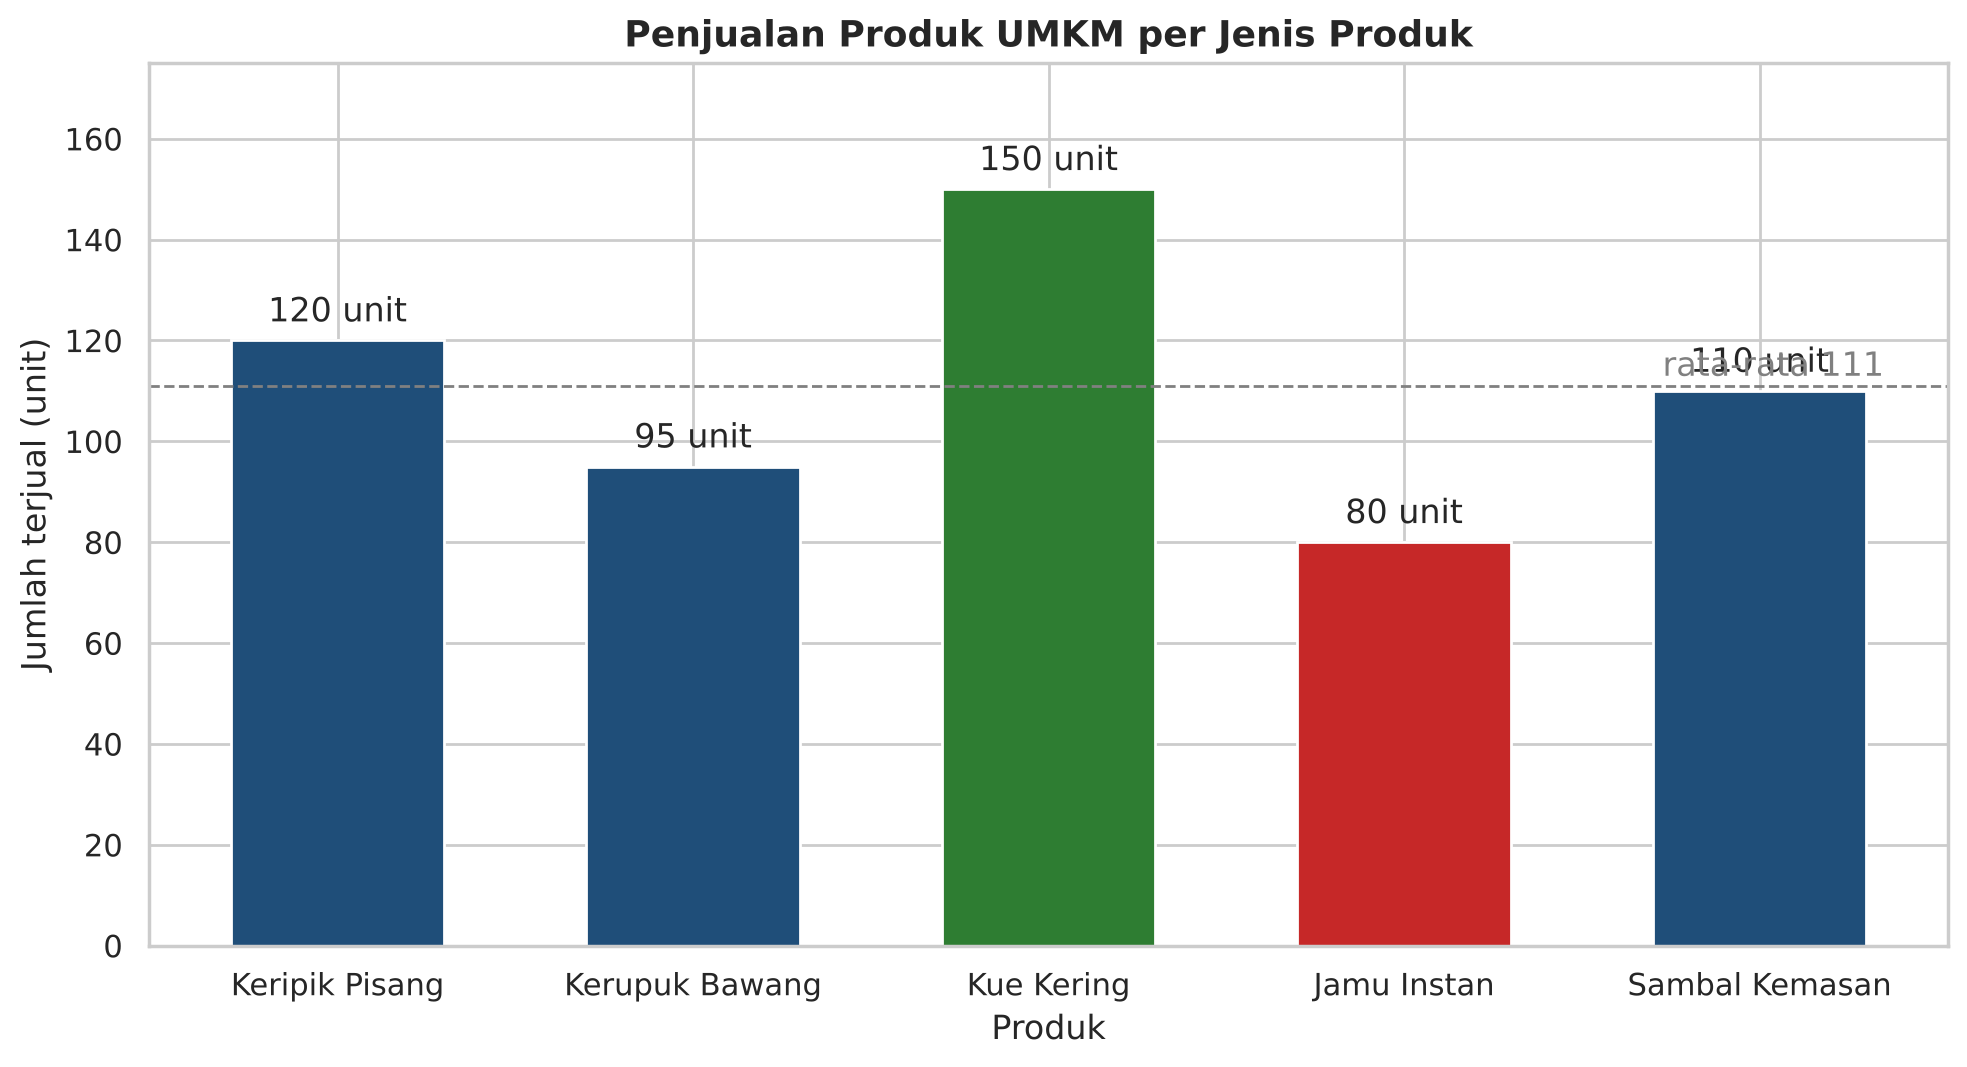

Tertinggi : Kue Kering = 150 unit (27.0% dari total 555 unit)
Terendah  : Jamu Instan = 80 unit (14.4% dari total)
Selisih   : 70 unit


In [2]:
# a. Data penjualan disimpan dalam variabel Python (list), lalu dirangkum dalam DataFrame
nama_produk = ["Keripik Pisang", "Kerupuk Bawang", "Kue Kering", "Jamu Instan", "Sambal Kemasan"]
unit_terjual = [120, 95, 150, 80, 110]
umkm = pd.DataFrame({"Produk": nama_produk, "Unit Terjual": unit_terjual})
display(umkm)

# b–c. Bar chart dengan judul, label sumbu, dan label nilai.
#      Produk tertinggi diberi warna hijau, terendah merah, sisanya biru.
idx_maks, idx_min = umkm["Unit Terjual"].idxmax(), umkm["Unit Terjual"].idxmin()
warna = [WARNA_NAIK if i == idx_maks else WARNA_TURUN if i == idx_min else WARNA_UTAMA for i in umkm.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
batang = ax.bar(umkm["Produk"], umkm["Unit Terjual"], color=warna, edgecolor="white", width=0.6)
ax.bar_label(batang, fmt="%d unit", padding=4)
ax.axhline(umkm["Unit Terjual"].mean(), ls="--", lw=1, color="grey")
ax.text(4.35, umkm["Unit Terjual"].mean() + 2, f"rata-rata {umkm['Unit Terjual'].mean():.0f}", ha="right", color="grey")
ax.set_title("Penjualan Produk UMKM per Jenis Produk")
ax.set_xlabel("Produk")
ax.set_ylabel("Jumlah terjual (unit)")
ax.set_ylim(0, 175)
plt.tight_layout()
plt.show()

# d. Produk dengan penjualan tertinggi dan terendah
tinggi, rendah = umkm.loc[idx_maks], umkm.loc[idx_min]
total = umkm["Unit Terjual"].sum()
print(f"Tertinggi : {tinggi['Produk']} = {tinggi['Unit Terjual']} unit ({tinggi['Unit Terjual']/total:.1%} dari total {total} unit)")
print(f"Terendah  : {rendah['Produk']} = {rendah['Unit Terjual']} unit ({rendah['Unit Terjual']/total:.1%} dari total)")
print(f"Selisih   : {tinggi['Unit Terjual'] - rendah['Unit Terjual']} unit")

**Interpretasi Soal 2.** Kue Kering menjadi produk paling laku (150 unit), sedangkan Jamu Instan paling sedikit terjual (80 unit), selisih 70 unit. Tiga produk (Kue Kering, Keripik Pisang, Sambal Kemasan) berada di atas rata-rata 111 unit, sementara Kerupuk Bawang dan Jamu Instan berada di bawahnya sehingga layak diprioritaskan untuk evaluasi promosi, harga, atau kemasan.

# SOAL 3 — Line Chart Tren Penjualan Toko Online

,Bulan,Penjualan (juta Rp),Perubahan (juta Rp),Perubahan (%)
0,Januari,10,NaN,NaN
1,Februari,12,2.0,20.0
2,Maret,15,3.0,25.0
3,April,13,-2.0,-13.3
4,Mei,18,5.0,38.5
5,Juni,22,4.0,22.2


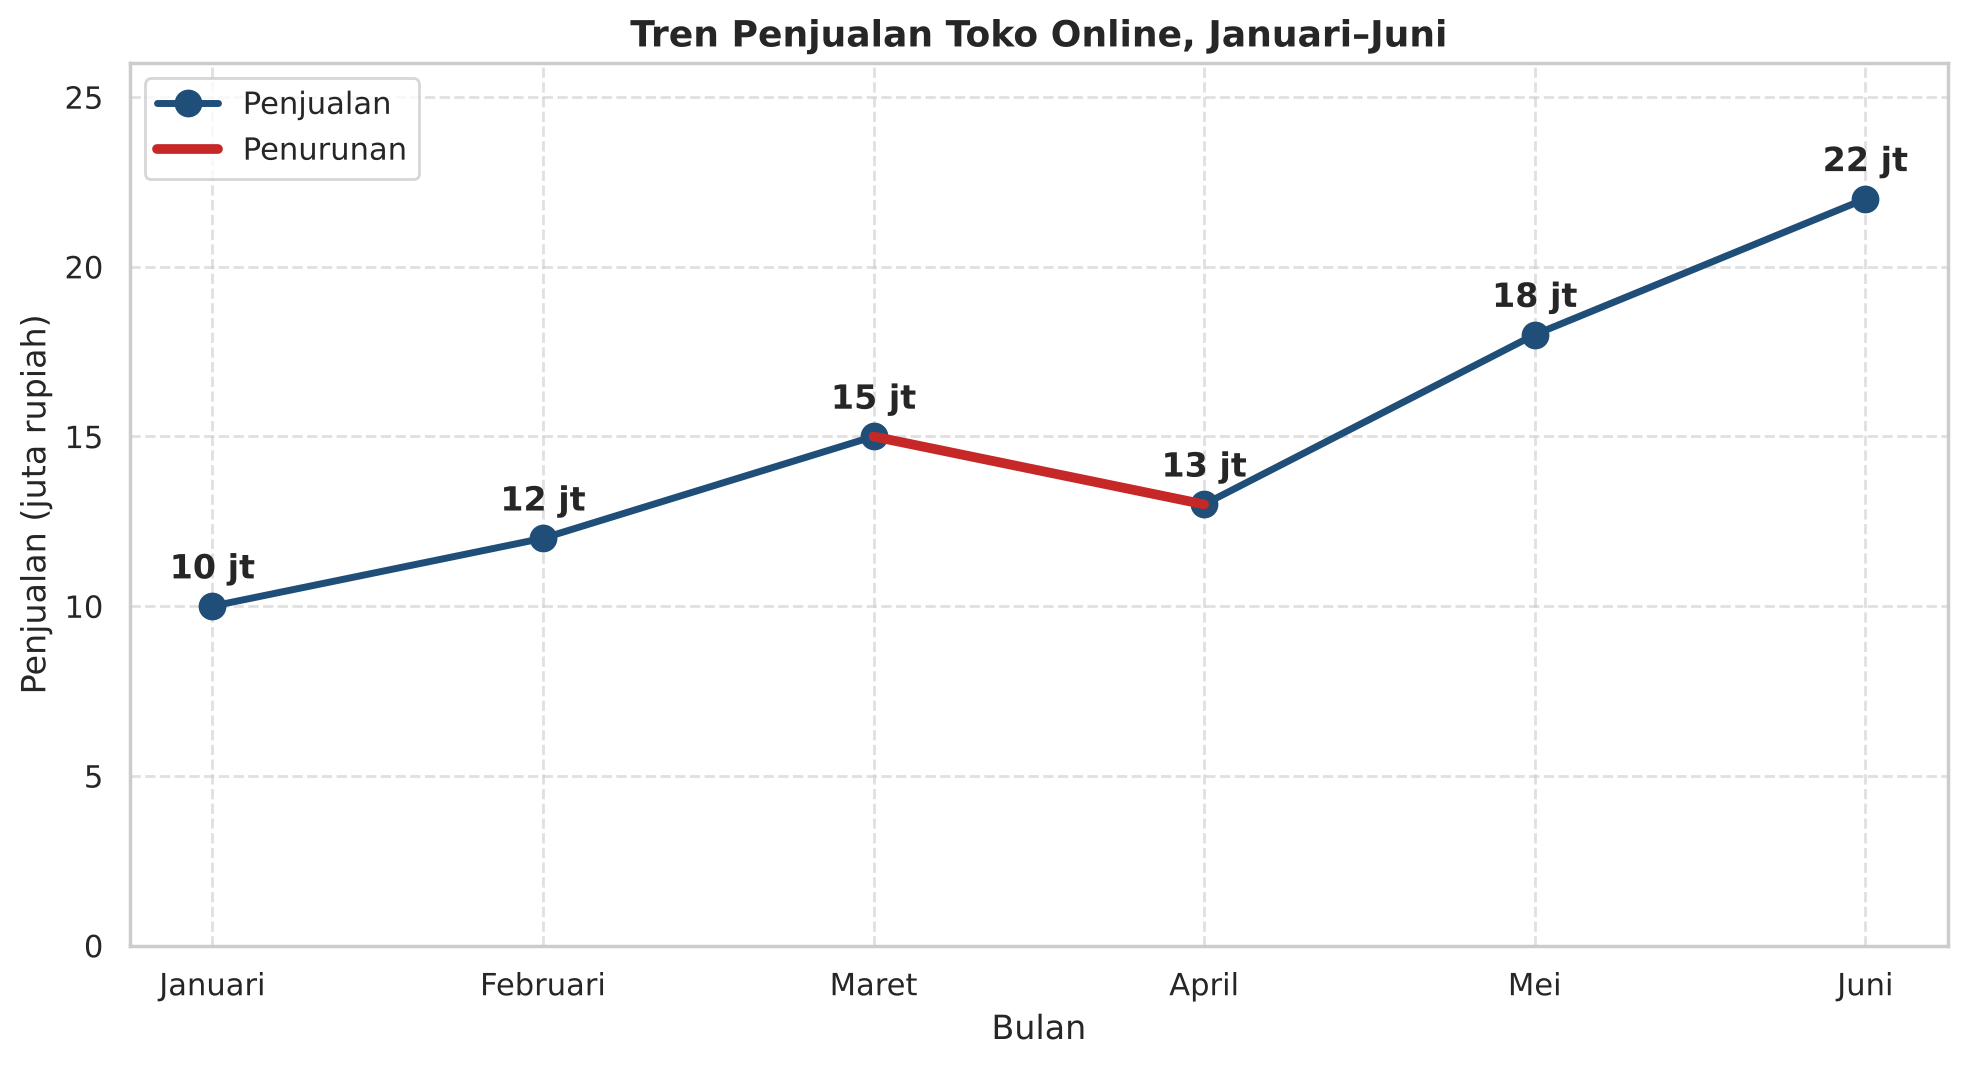

Penurunan terjadi pada April: dari 15 menjadi 13 juta (-2 juta / -13.3%)
Kenaikan Januari ke Juni = (22 - 10) / 10 x 100% = 120%


In [3]:
bulan = ["Januari", "Februari", "Maret", "April", "Mei", "Juni"]
omzet = [10, 12, 15, 13, 18, 22]   # juta rupiah
tren = pd.DataFrame({"Bulan": bulan, "Penjualan (juta Rp)": omzet})
tren["Perubahan (juta Rp)"] = tren["Penjualan (juta Rp)"].diff()
tren["Perubahan (%)"] = (tren["Penjualan (juta Rp)"].pct_change() * 100).round(1)
display(tren)

# a–b. Line chart dengan marker dan grid; ruas yang turun diberi warna merah
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(bulan, omzet, marker="o", markersize=9, lw=2.5, color=WARNA_UTAMA, label="Penjualan")
for i in range(1, len(omzet)):
    if omzet[i] < omzet[i - 1]:
        ax.plot(bulan[i-1:i+1], omzet[i-1:i+1], lw=3.5, color=WARNA_TURUN, label="Penurunan")
for x, y in zip(bulan, omzet):
    ax.annotate(f"{y} jt", (x, y), xytext=(0, 10), textcoords="offset points", ha="center", fontweight="bold")
ax.set_title("Tren Penjualan Toko Online, Januari–Juni")
ax.set_xlabel("Bulan")
ax.set_ylabel("Penjualan (juta rupiah)")
ax.set_ylim(0, 26)
ax.grid(True, ls="--", alpha=0.6)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# c. Bulan yang mengalami penurunan
turun = tren[tren["Perubahan (juta Rp)"] < 0]
for i, r in turun.iterrows():
    print(f"Penurunan terjadi pada {r['Bulan']}: dari {omzet[i-1]} menjadi {r['Penjualan (juta Rp)']} juta "
          f"({r['Perubahan (juta Rp)']:+.0f} juta / {r['Perubahan (%)']:+.1f}%)")

# d. Persentase kenaikan Januari -> Juni
kenaikan = (omzet[-1] - omzet[0]) / omzet[0] * 100
print(f"Kenaikan Januari ke Juni = ({omzet[-1]} - {omzet[0]}) / {omzet[0]} x 100% = {kenaikan:.0f}%")

**Interpretasi dan rekomendasi Soal 3.** Penjualan naik dari 10 juta (Januari) menjadi 22 juta (Juni), atau **naik 120%**. Satu-satunya penurunan terjadi pada **April** (15 → 13 juta, −13,3%), lalu penjualan pulih dan naik tajam pada Mei–Juni.

1. **Cari tahu pemicu lonjakan Mei–Juni** (promo, produk baru, momen musiman) dan ulangi pemicu yang terbukti berhasil.
2. **Antisipasi penurunan seperti April** dengan memantau penjualan mingguan dan menyiapkan promo cadangan sebelum bulan yang rawan turun.

# SOAL 4 — Pandas dan Seaborn: Data Enam Mahasiswa

In [4]:
# a. DataFrame dari data soal
mhs = pd.DataFrame({
    "Mahasiswa": list("ABCDEF"),
    "Jam Belajar": [1, 2, 3, 4, 5, 6],
    "Kehadiran (%)": [60, 70, 75, 80, 90, 95],
    "Nilai Ujian": [55, 60, 65, 70, 85, 90],
})

# b. Lima data pertama dan struktur data
display(mhs.head())
mhs.info()
display(mhs.describe().round(2))

,Mahasiswa,Jam Belajar,Kehadiran (%),Nilai Ujian
0,A,1,60,55
1,B,2,70,60
2,C,3,75,65
3,D,4,80,70
4,E,5,90,85


<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Mahasiswa      6 non-null      str  
 1   Jam Belajar    6 non-null      int64
 2   Kehadiran (%)  6 non-null      int64
 3   Nilai Ujian    6 non-null      int64
dtypes: int64(3), str(1)
memory usage: 324.0 bytes


,Jam Belajar,Kehadiran (%),Nilai Ujian
count,6.00,6.00,6.00
mean,3.50,78.33,70.83
std,1.87,12.91,13.93
min,1.00,60.00,55.00
25%,2.25,71.25,61.25
50%,3.50,77.50,67.50
75%,4.75,87.50,81.25
max,6.00,95.00,90.00


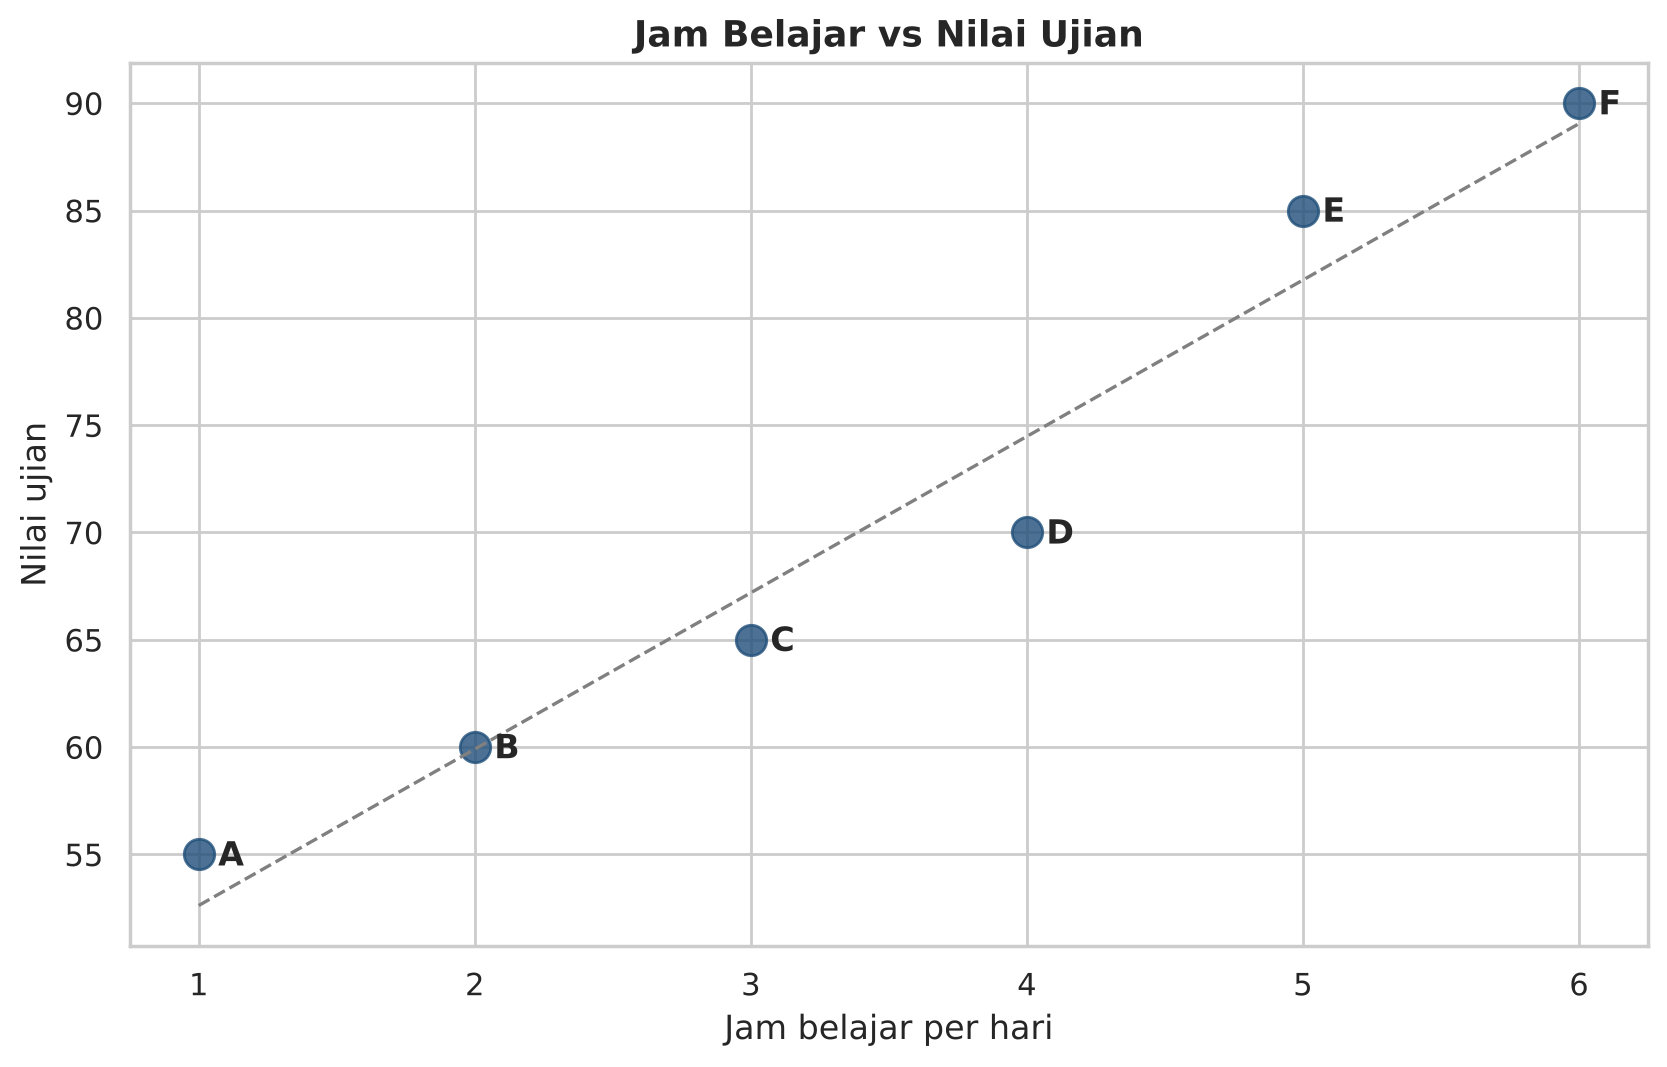

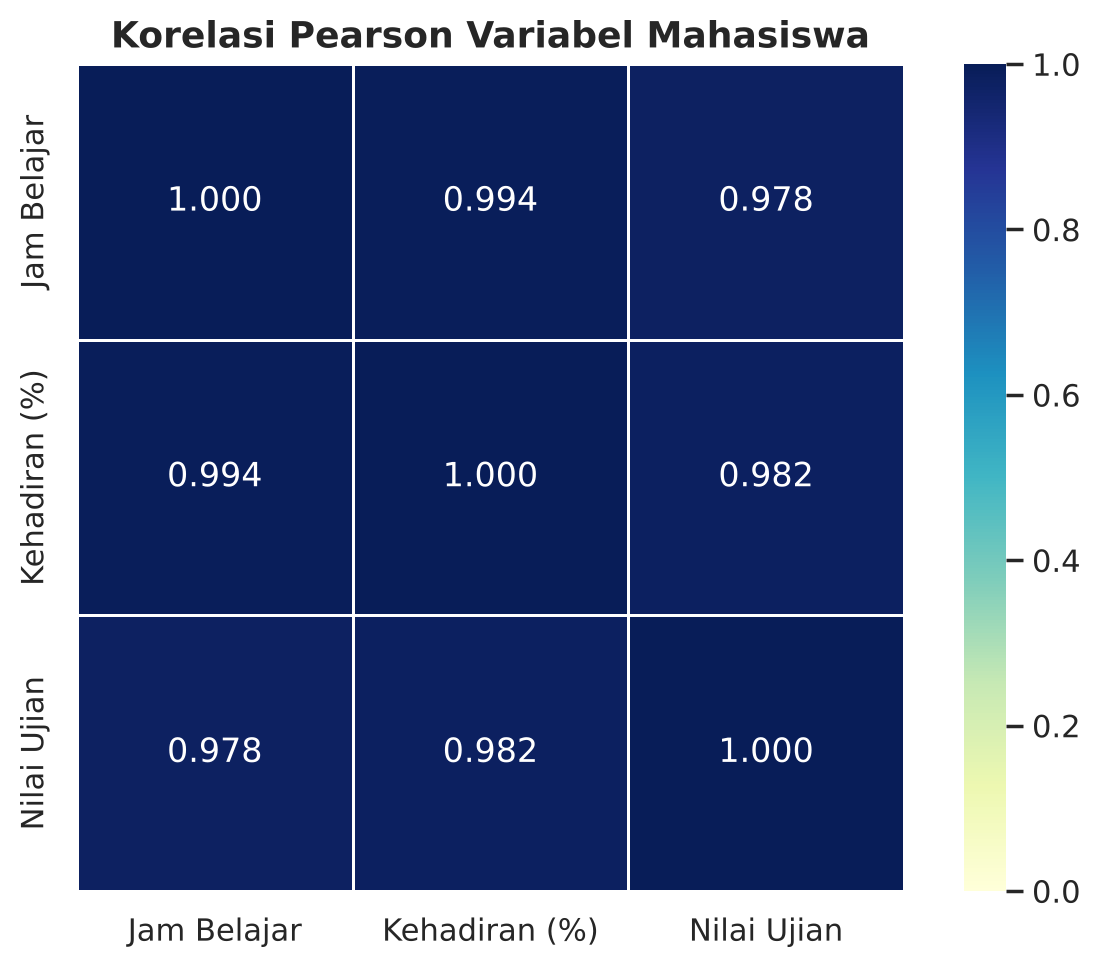

r(Jam Belajar, Nilai)   = 0.978
r(Kehadiran, Nilai)     = 0.982
r(Jam Belajar, Kehadiran) = 0.994
Kemiringan garis tren: setiap +1 jam belajar ~ +7.3 poin nilai


In [5]:
# c. Scatter plot jam belajar vs nilai ujian (Seaborn) + garis tren
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.regplot(data=mhs, x="Jam Belajar", y="Nilai Ujian", ci=None, ax=ax,
            scatter_kws={"s": 120, "color": WARNA_UTAMA}, line_kws={"color": "grey", "ls": "--", "lw": 1.2})
for _, r in mhs.iterrows():
    ax.annotate(r["Mahasiswa"], (r["Jam Belajar"], r["Nilai Ujian"]), xytext=(7, -4), textcoords="offset points", fontweight="bold")
ax.set_title("Jam Belajar vs Nilai Ujian")
ax.set_xlabel("Jam belajar per hari")
ax.set_ylabel("Nilai ujian")
plt.tight_layout()
plt.show()

# d. Heatmap korelasi Pearson antarvariabel numerik
kor = mhs[["Jam Belajar", "Kehadiran (%)", "Nilai Ujian"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(kor, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, linewidths=1, square=True, ax=ax)
ax.set_title("Korelasi Pearson Variabel Mahasiswa")
plt.tight_layout()
plt.show()

# e. Angka untuk interpretasi
kemiringan = np.polyfit(mhs["Jam Belajar"], mhs["Nilai Ujian"], 1)[0]
print(f"r(Jam Belajar, Nilai)   = {kor.loc['Jam Belajar', 'Nilai Ujian']:.3f}")
print(f"r(Kehadiran, Nilai)     = {kor.loc['Kehadiran (%)', 'Nilai Ujian']:.3f}")
print(f"r(Jam Belajar, Kehadiran) = {kor.loc['Jam Belajar', 'Kehadiran (%)']:.3f}")
print(f"Kemiringan garis tren: setiap +1 jam belajar ~ +{kemiringan:.1f} poin nilai")

**Interpretasi Soal 4.** Keenam titik membentuk pola naik yang hampir lurus: semakin lama jam belajar, semakin tinggi nilai (korelasi ≈ 0,98). Kehadiran juga berkorelasi sangat kuat dengan nilai, dan jam belajar sangat erat dengan kehadiran.

**Apakah ini sebab-akibat? Tidak dapat disimpulkan.**
1. Data hanya enam orang, sehingga pola yang rapi bisa muncul secara kebetulan.
2. Korelasi hanya menunjukkan dua hal bergerak bersama, bukan arah pengaruhnya.
3. Ada faktor lain yang tidak diukur, misalnya kemampuan awal, motivasi, dan cara belajar, yang dapat memengaruhi jam belajar sekaligus nilai.
4. Jam belajar dan kehadiran saling berkaitan sangat erat, sehingga pengaruh masing-masing tidak dapat dipisahkan.

Hubungan sebab-akibat memerlukan data yang lebih banyak dan desain penelitian yang mengendalikan faktor lain, misalnya eksperimen.

# SOAL 5 — Studi Kasus Analisis Data: Harga Saham BBCA

## 5.1 Tujuan dan sumber data
Studi kasus ini menganalisis **kinerja harga saham PT Bank Central Asia Tbk (kode BBCA, ticker Yahoo `BBCA.JK`)** pada periode **2 Januari 2020 – 28 Oktober 2026**. Pertanyaan yang dijawab:
1. Bagaimana tren harga jangka panjang dan kapan titik tertinggi/terendahnya?
2. Bagaimana kinerja (return) BBCA dari tahun ke tahun?
3. Seberapa besar dan bagaimana sebaran pergerakan harga harian (risiko)?
4. Apakah volume perdagangan berhubungan dengan besarnya pergerakan harga?
5. Apakah ada pola bulanan (musiman) pada return?

**Sumber data.** Data harian OHLCV (Open, High, Low, Close, Volume) dikumpulkan dari dua sumber publik:

| Periode | Sumber | Keterangan |
|---|---|---|
| 2 Jan 2020 – 25 Jun 2025 | Data historis Investing.com | diambil dari salinan publik di GitHub (`kaaayeess-sketch/MarketPulseIDX`) |
| 26 Jun 2025 – 28 Okt 2026 | Yahoo Finance (`BBCA.JK`) | hasil *scraping* harian yang diarsipkan di GitHub (`SeedFlora/idx-daily-data`, `darwix/ihsg-price`) |

Pada 129 hari yang tersedia di kedua sumber (26 Juni – 30 Desember 2025), nilai Open, High, Low, dan Close **identik**, dan volume berbeda kurang dari 0,04% (pembulatan). Harga sudah disesuaikan dengan pemecahan saham (*stock split*) 1:5 tahun 2021. Hasil gabungan disimpan sebagai `BBCA_JK_2020_2026.csv` agar analisis dapat diulang dengan angka yang sama.

> Set `AMBIL_ULANG_DARI_YAHOO = True` untuk mengambil ulang data langsung dari Yahoo Finance dengan `yfinance` (memerlukan internet; angka bisa sedikit berbeda dari laporan karena data terbaru ikut terambil).

In [6]:
AMBIL_ULANG_DARI_YAHOO = False
TICKER, MULAI = "BBCA.JK", "2020-01-01"
NAMA_CSV = "BBCA_JK_2020_2026.csv"

if AMBIL_ULANG_DARI_YAHOO:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yfinance"], check=True)
    import yfinance as yf
    unduh = yf.download(TICKER, start=MULAI, auto_adjust=False, progress=False)
    unduh.columns = unduh.columns.get_level_values(0)
    saham_asli = (unduh.reset_index()[["Date", "Open", "High", "Low", "Close", "Volume"]]
                  .assign(Source="Yahoo Finance"))
    saham_asli.to_csv(NAMA_CSV, index=False)
    print(f"Data diambil ulang dari Yahoo Finance dan disimpan ke {NAMA_CSV}")
else:
    lokasi = [Path(NAMA_CSV), Path("/content") / NAMA_CSV, Path("data") / NAMA_CSV]
    path_csv = next((p for p in lokasi if p.exists()), None)
    if path_csv is None:
        try:
            from google.colab import files
            print(f"Unggah file {NAMA_CSV}:")
            path_csv = Path(next(iter(files.upload())))
        except ImportError:
            raise FileNotFoundError(f"{NAMA_CSV} tidak ditemukan. Letakkan file di folder yang sama dengan notebook.")
    saham_asli = pd.read_csv(path_csv)
    print("File data:", path_csv)

print("Ukuran data:", saham_asli.shape)

File data: BBCA_JK_2020_2026.csv
Ukuran data: (1637, 7)


## 5.2 Pemeriksaan struktur dan kualitas data
Sebelum divisualisasikan, data diperiksa: nama dan tipe kolom, contoh baris, statistik deskriptif, nilai kosong, duplikasi tanggal, dan syarat minimal 100 baris.

In [7]:
saham_asli.info()
display(saham_asli.head())
display(saham_asli.tail())
display(saham_asli.describe().T.round(2))

kosong = saham_asli.isna().sum()
print("Nilai kosong per kolom:", kosong[kosong > 0].to_dict() or "tidak ada")
print("Baris duplikat persis   :", int(saham_asli.duplicated().sum()))
print("Tanggal duplikat        :", int(saham_asli["Date"].duplicated().sum()))
print("Jumlah baris            :", len(saham_asli), "->", "memenuhi" if len(saham_asli) >= 100 else "TIDAK memenuhi", "syarat minimal 100 baris")
print("Komposisi sumber        :", saham_asli["Source"].value_counts().to_dict())

display(pd.DataFrame({
    "Variabel": ["Date", "Open", "High", "Low", "Close", "Volume"],
    "Tipe": ["tanggal", "numerik (Rp)", "numerik (Rp)", "numerik (Rp)", "numerik (Rp)", "numerik (lembar)"],
    "Kegunaan": ["sumbu waktu, pengelompokan tahun & bulan", "harga pembukaan", "harga tertinggi harian",
                 "harga terendah harian", "harga penutupan: dasar tren, return, dan MA", "aktivitas perdagangan"],
}))

<class 'pandas.DataFrame'>
RangeIndex: 1637 entries, 0 to 1636
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1637 non-null   str    
 1   Open    1637 non-null   float64
 2   High    1637 non-null   float64
 3   Low     1637 non-null   float64
 4   Close   1637 non-null   float64
 5   Volume  1637 non-null   int64  
 6   Source  1637 non-null   str    
dtypes: float64(4), int64(1), str(2)
memory usage: 89.7 KB


,Date,Open,High,Low,Close,Volume,Source
0,2020-01-02,6695.0,6780.0,6680.0,6690.0,49450000,Investing.com
1,2020-01-03,6750.0,6800.0,6725.0,6800.0,47760000,Investing.com
2,2020-01-06,6720.0,6750.0,6690.0,6735.0,27300000,Investing.com
3,2020-01-07,6735.0,6770.0,6730.0,6740.0,45020000,Investing.com
4,2020-01-08,6670.0,6745.0,6670.0,6680.0,53690000,Investing.com


,Date,Open,High,Low,Close,Volume,Source
1632,2026-10-22,5125.0,5275.0,5100.0,5175.0,286928500,Yahoo Finance
1633,2026-10-23,5175.0,5225.0,5000.0,5025.0,495623900,Yahoo Finance
1634,2026-10-26,5025.0,5075.0,4940.0,4940.0,353641200,Yahoo Finance
1635,2026-10-27,4940.0,4980.0,4800.0,4900.0,366846200,Yahoo Finance
1636,2026-10-28,4920.0,5325.0,4920.0,5275.0,583695400,Yahoo Finance


,count,mean,std,min,25%,50%,75%,max
Open,1637.0,7.845240e+03,1438.82,4450.0,6540.0,7900.0,9000.0,1.090000e+04
High,1637.0,7.922100e+03,1437.29,4800.0,6585.0,7975.0,9050.0,1.095000e+04
Low,1637.0,7.768460e+03,1442.26,4325.0,6480.0,7825.0,8925.0,1.077500e+04
Close,1637.0,7.842200e+03,1441.18,4430.0,6530.0,7925.0,9000.0,1.095000e+04
Volume,1637.0,1.080339e+08,98945247.40,0.0,61480000.0,83900000.0,119980000.0,1.432993e+09


Nilai kosong per kolom: tidak ada
Baris duplikat persis   : 0
Tanggal duplikat        : 0
Jumlah baris            : 1637 -> memenuhi syarat minimal 100 baris
Komposisi sumber        : {'Investing.com': 1318, 'Yahoo Finance': 319}


,Variabel,Tipe,Kegunaan
0,Date,tanggal,"sumbu waktu, pengelompokan tahun & bulan"
1,Open,numerik (Rp),harga pembukaan
2,High,numerik (Rp),harga tertinggi harian
3,Low,numerik (Rp),harga terendah harian
4,Close,numerik (Rp),"harga penutupan: dasar tren, return, dan MA"
5,Volume,numerik (lembar),aktivitas perdagangan


## 5.3 Penyiapan data dan variabel turunan
Kolom tanggal dikonversi ke `datetime` dan data diurutkan. Baris hari libur bursa yang tercatat dengan volume 0 dan harga datar dikeluarkan. Setelah itu dibuat variabel turunan:

- **Return harian (%)** = (Close hari ini − Close kemarin) / Close kemarin × 100
- **MA50 dan MA200**: rata-rata bergerak harga penutupan 50 dan 200 hari bursa
- **Volatilitas 20 hari (tahunan, %)** = simpangan baku return 20 hari × √252
- **Drawdown (%)**: jarak harga saat ini dari harga tertinggi sebelumnya

In [8]:
saham = saham_asli.copy()
saham["Date"] = pd.to_datetime(saham["Date"])
saham = saham.sort_values("Date").drop_duplicates("Date").set_index("Date")
for k in ["Open", "High", "Low", "Close", "Volume"]:
    saham[k] = pd.to_numeric(saham[k], errors="coerce")
saham = saham.dropna(subset=["Close"])

# Baris dengan volume 0 dan harga datar (Open = High = Low = Close) adalah hari libur bursa
# yang tetap tercatat oleh Yahoo Finance, sehingga dikeluarkan dari analisis.
bukan_hari_bursa = (saham["Volume"] == 0) & (saham["High"] == saham["Low"])
print("Baris hari libur (volume 0) yang dikeluarkan:", int(bukan_hari_bursa.sum()),
      [f"{t:%d %b %Y}" for t in saham.index[bukan_hari_bursa]])
saham = saham[~bukan_hari_bursa]

saham["Return (%)"] = saham["Close"].pct_change() * 100
saham["MA50"] = saham["Close"].rolling(50).mean()
saham["MA200"] = saham["Close"].rolling(200).mean()
saham["Volatilitas 20H (%)"] = saham["Return (%)"].rolling(20).std() * np.sqrt(252)
saham["Drawdown (%)"] = (saham["Close"] / saham["Close"].cummax() - 1) * 100
saham["Volume (juta)"] = saham["Volume"] / 1e6
saham["Tahun"] = saham.index.year
saham["Bulan"] = saham.index.month

print(f"Periode  : {saham.index.min():%d %b %Y} s.d. {saham.index.max():%d %b %Y}")
print(f"Hari bursa: {len(saham):,}")
display(saham.groupby("Tahun").size().rename("Jumlah hari bursa").to_frame().T)

Baris hari libur (volume 0) yang dikeluarkan: 4 ['14 May 2026', '15 May 2026', '27 May 2026', '28 May 2026']
Periode  : 02 Jan 2020 s.d. 28 Oct 2026
Hari bursa: 1,633


Tahun,2020,2021,2022,2023,2024,2025,2026
Jumlah hari bursa,242,247,246,239,237,236,186


## 5.4 Visualisasi 1 — Tren harga penutupan dan rata-rata bergerak
Line chart dipakai karena data berurutan menurut waktu. Garis MA50 dan MA200 membantu membaca arah tren di balik fluktuasi harian.

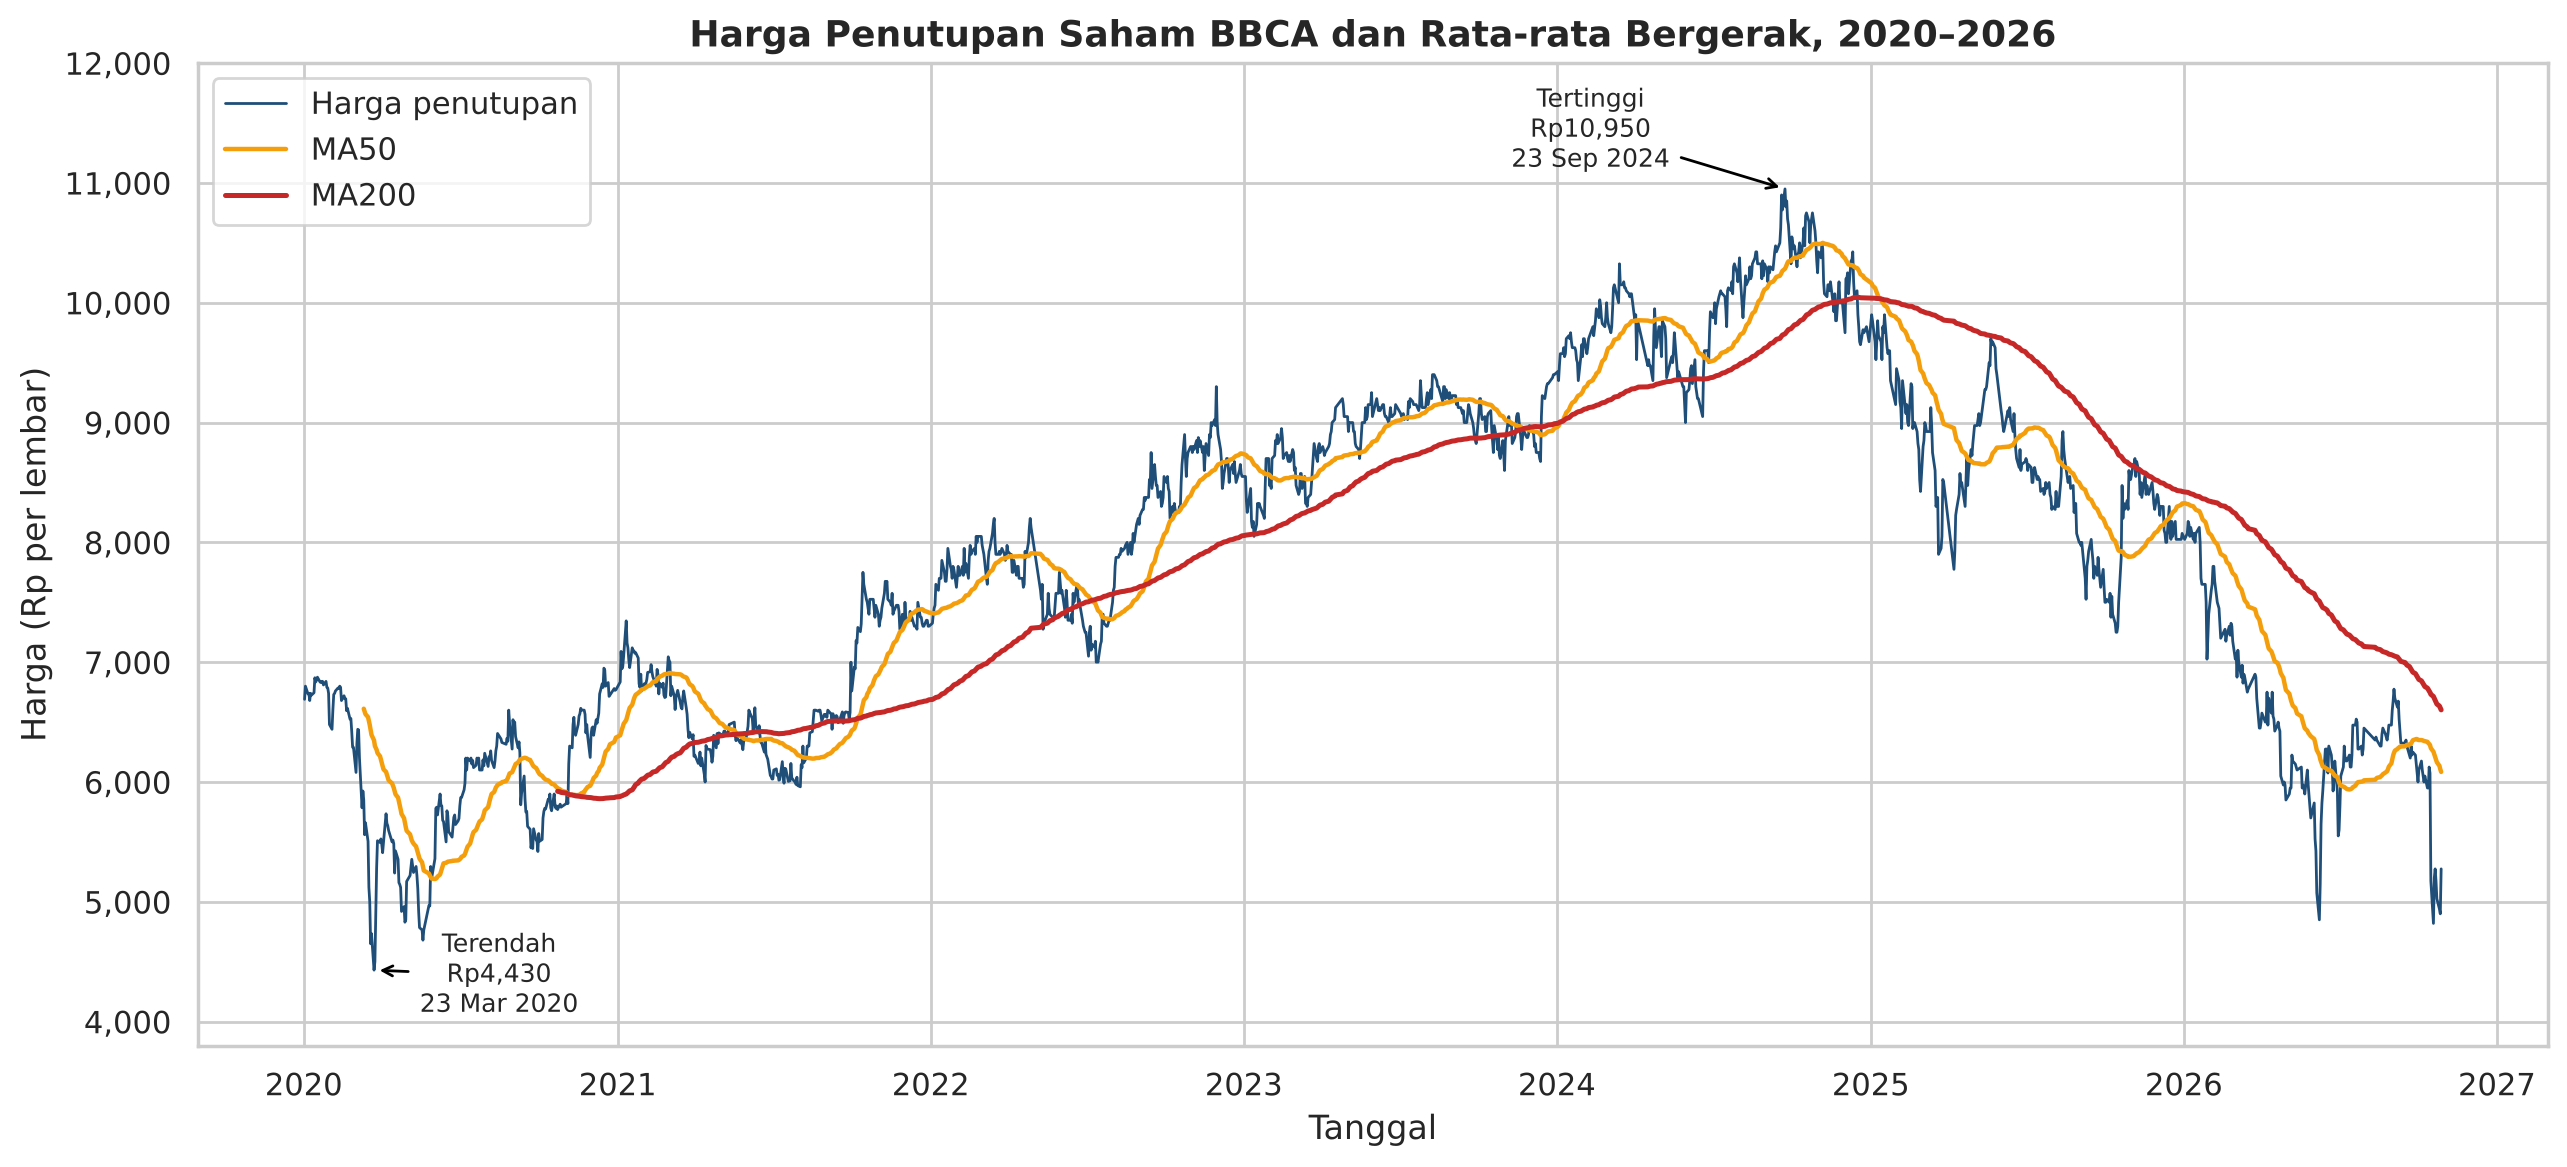

Harga awal (02 Jan 2020): Rp6,690 | Harga akhir (28 Oct 2026): Rp5,275 | Perubahan: -21.2%
Tertinggi: Rp10,950 (23 Sep 2024) | Terendah: Rp4,430 (23 Mar 2020)
Drawdown terdalam: -56.0% pada 19 Oct 2026
Posisi terakhir terhadap MA200: -20.1%


In [9]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(saham.index, saham["Close"], lw=1, color=WARNA_UTAMA, label="Harga penutupan")
ax.plot(saham.index, saham["MA50"], lw=1.6, color="#f59e0b", label="MA50")
ax.plot(saham.index, saham["MA200"], lw=1.8, color=WARNA_TURUN, label="MA200")

t_maks, t_min = saham["Close"].idxmax(), saham["Close"].idxmin()
for t, teks, off in [(t_maks, "Tertinggi", (-70, 8)), (t_min, "Terendah", (45, -15))]:
    ax.annotate(f"{teks}\nRp{saham.loc[t, 'Close']:,.0f}\n{t:%d %b %Y}", (t, saham.loc[t, "Close"]),
                xytext=off, textcoords="offset points", ha="center", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="black"))
ax.set_title("Harga Penutupan Saham BBCA dan Rata-rata Bergerak, 2020–2026")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga (Rp per lembar)")
ax.set_ylim(3800, 12000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

awal, akhir = saham["Close"].iloc[0], saham["Close"].iloc[-1]
print(f"Harga awal (02 Jan 2020): Rp{awal:,.0f} | Harga akhir ({saham.index[-1]:%d %b %Y}): Rp{akhir:,.0f} | Perubahan: {(akhir/awal-1)*100:+.1f}%")
print(f"Tertinggi: Rp{saham['Close'].max():,.0f} ({t_maks:%d %b %Y}) | Terendah: Rp{saham['Close'].min():,.0f} ({t_min:%d %b %Y})")
print(f"Drawdown terdalam: {saham['Drawdown (%)'].min():.1f}% pada {saham['Drawdown (%)'].idxmin():%d %b %Y}")
print(f"Posisi terakhir terhadap MA200: {(akhir / saham['MA200'].iloc[-1] - 1)*100:+.1f}%")

## 5.5 Visualisasi 2 — Return tahunan
Bar chart membandingkan kinerja setiap tahun (kategori). Return tahunan dihitung dari harga penutupan hari bursa terakhir tahun sebelumnya ke hari bursa terakhir tahun tersebut; tahun 2020 dihitung dari hari bursa pertama, dan 2026 hanya sampai 28 Oktober (*year-to-date*).

,Close awal,Close akhir,Return (%),Tertinggi,Terendah,Volatilitas (%),Rata-rata volume (juta)
Tahun,,,,,,,
2020,6690.0,6770.0,1.2,6950.0,4430.0,38.4,107.4
2021,6770.0,7300.0,7.8,7750.0,5960.0,23.2,81.6
2022,7300.0,8550.0,17.1,9300.0,7000.0,22.8,92.3
2023,8550.0,9400.0,9.9,9400.0,8050.0,17.5,74.2
2024,9400.0,9675.0,2.9,10950.0,9000.0,22.2,80.9
2025,9675.0,8075.0,-16.5,9900.0,7250.0,29.4,130.2
2026,8075.0,5275.0,-34.7,8175.0,4820.0,42.0,217.0


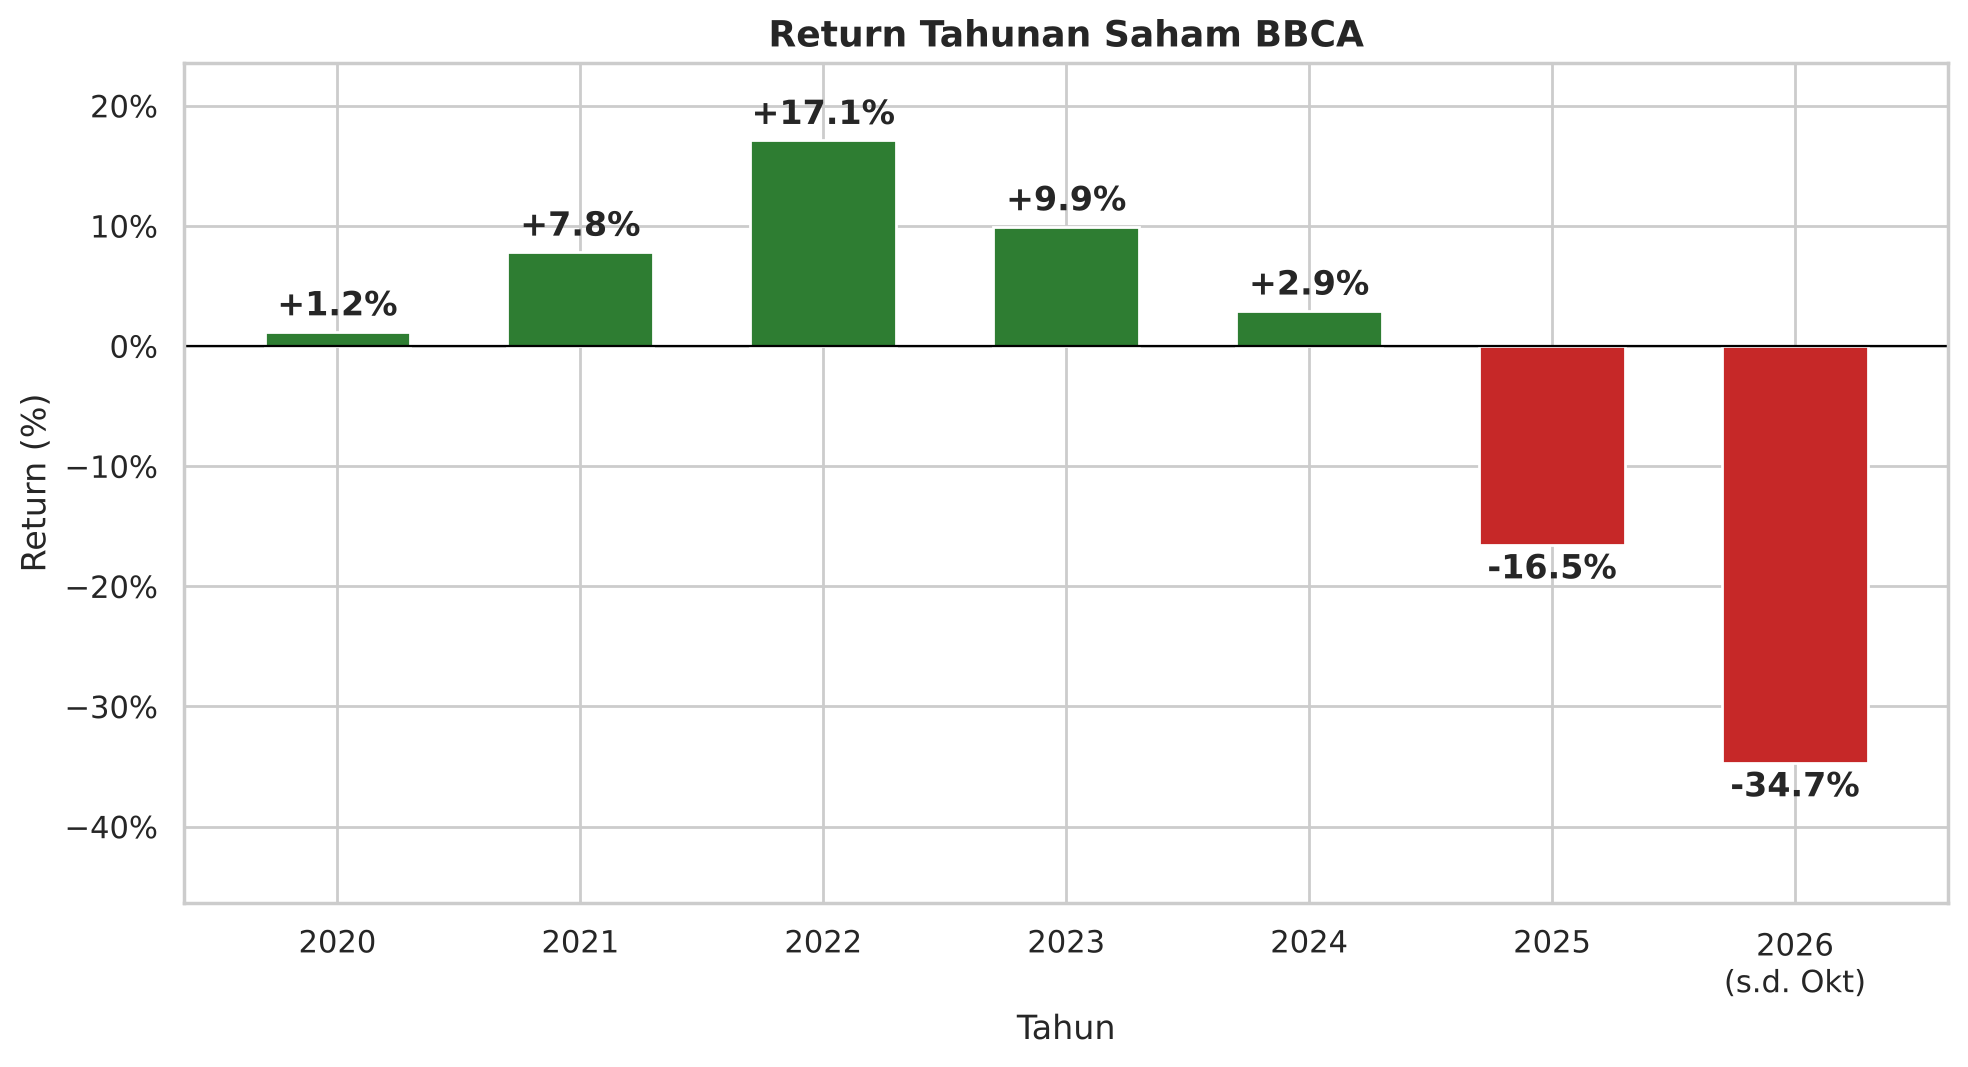

Tahun terbaik : 2022 (+17.1%)
Tahun terburuk: 2026 (-34.7%)
Tahun positif : 5 dari 7


In [10]:
akhir_tahun = saham["Close"].groupby(saham["Tahun"]).last()
dasar = akhir_tahun.shift(1)
dasar.iloc[0] = saham["Close"].iloc[0]
ringkas_tahun = pd.DataFrame({
    "Close awal": dasar, "Close akhir": akhir_tahun,
    "Return (%)": (akhir_tahun / dasar - 1) * 100,
    "Tertinggi": saham["Close"].groupby(saham["Tahun"]).max(),
    "Terendah": saham["Close"].groupby(saham["Tahun"]).min(),
    "Volatilitas (%)": saham.groupby("Tahun")["Return (%)"].std() * np.sqrt(252),
    "Rata-rata volume (juta)": saham.groupby("Tahun")["Volume (juta)"].mean(),
})
display(ringkas_tahun.round(1))

fig, ax = plt.subplots(figsize=(10, 5.5))
label_tahun = [f"{t}" if t < saham["Tahun"].max() else f"{t}\n(s.d. Okt)" for t in ringkas_tahun.index]
warna = [WARNA_NAIK if v >= 0 else WARNA_TURUN for v in ringkas_tahun["Return (%)"]]
b = ax.bar(label_tahun, ringkas_tahun["Return (%)"], color=warna, width=0.6)
ax.bar_label(b, labels=[f"{v:+.1f}%" for v in ringkas_tahun["Return (%)"]], padding=3, fontweight="bold")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Return Tahunan Saham BBCA")
ax.set_xlabel("Tahun")
ax.set_ylabel("Return (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
lo, hi = ringkas_tahun["Return (%)"].min(), ringkas_tahun["Return (%)"].max()
ax.set_ylim(min(0, lo) * 1.25 - 3, max(0, hi) * 1.2 + 3)
plt.tight_layout()
plt.show()

terbaik, terburuk = ringkas_tahun["Return (%)"].idxmax(), ringkas_tahun["Return (%)"].idxmin()
print(f"Tahun terbaik : {terbaik} ({ringkas_tahun.loc[terbaik, 'Return (%)']:+.1f}%)")
print(f"Tahun terburuk: {terburuk} ({ringkas_tahun.loc[terburuk, 'Return (%)']:+.1f}%)")
print(f"Tahun positif : {(ringkas_tahun['Return (%)'] > 0).sum()} dari {len(ringkas_tahun)}")

## 5.6 Visualisasi 3 — Sebaran return harian
Histogram memperlihatkan seberapa sering besaran perubahan harga harian terjadi. Semakin lebar sebaran, semakin besar risiko pergerakan harian.

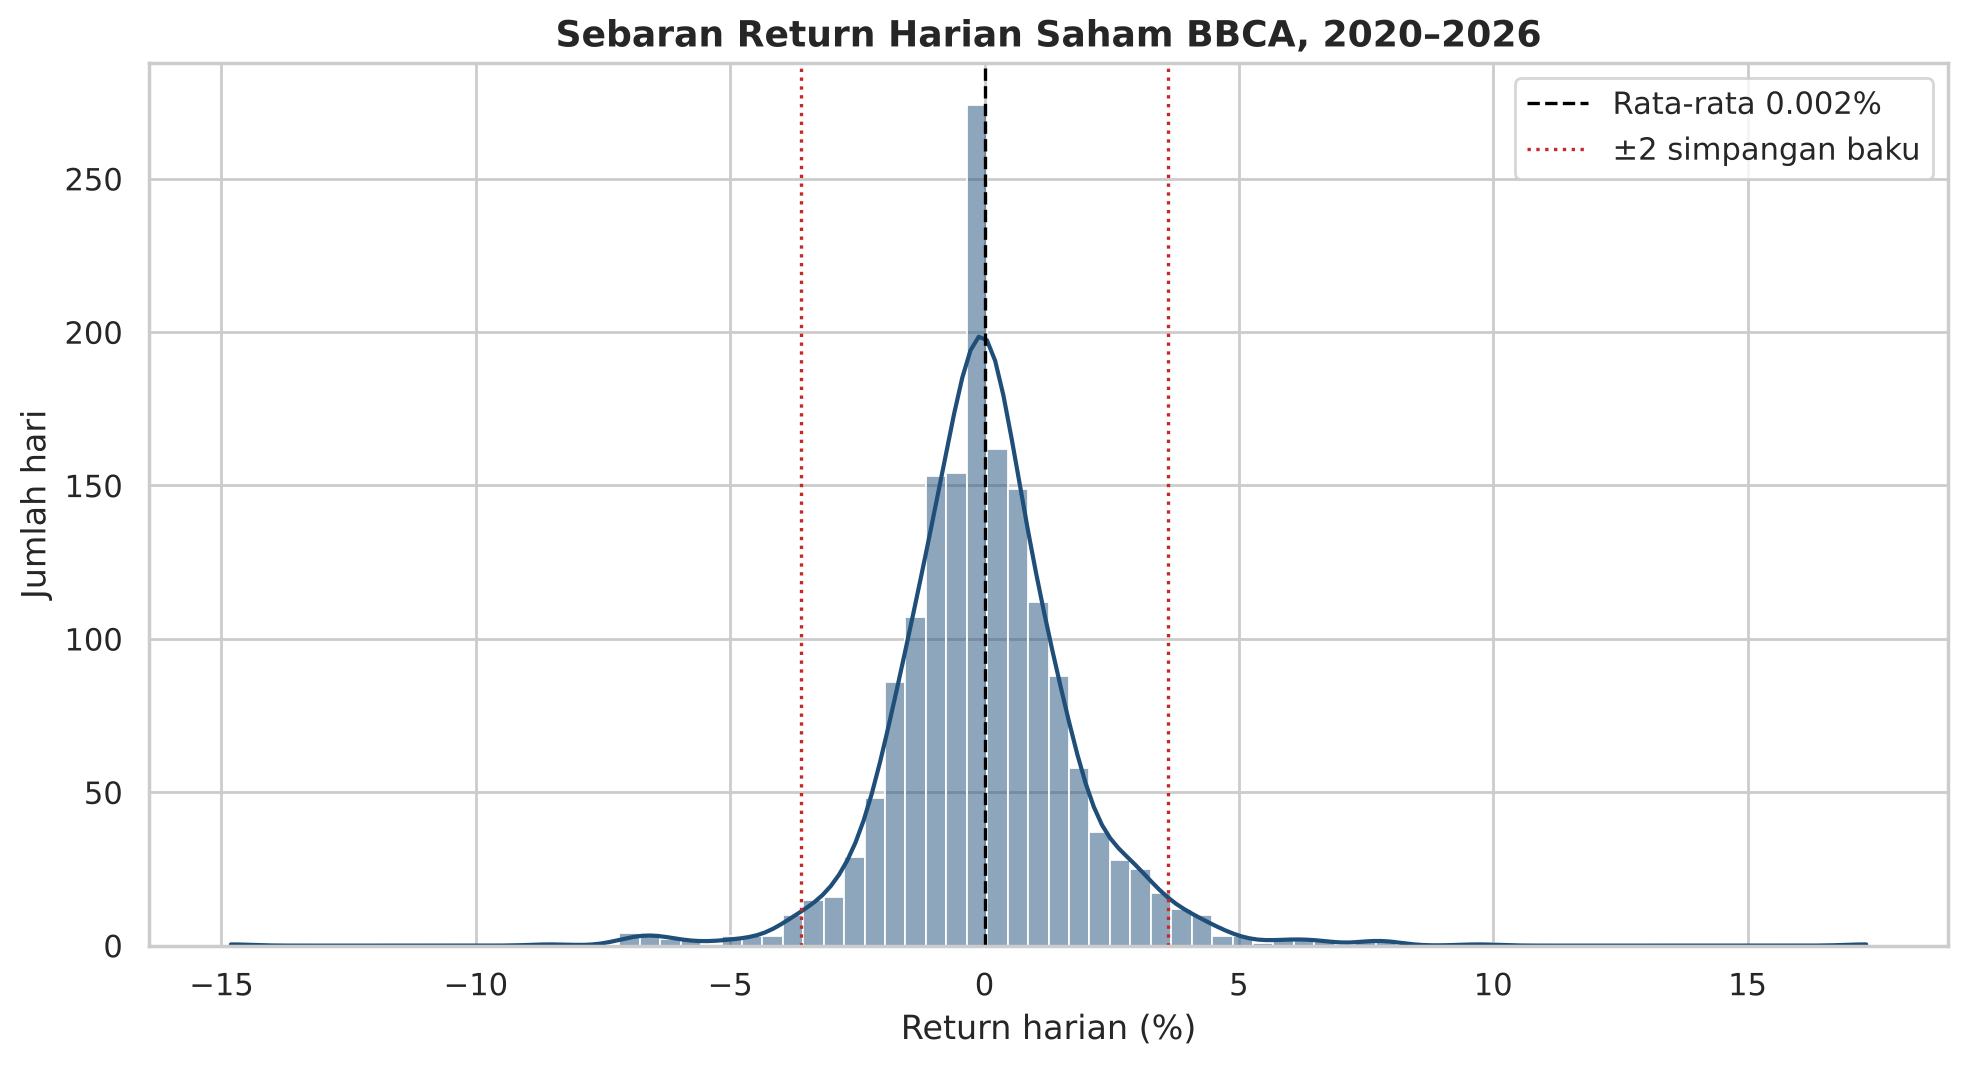

,Nilai
Rata-rata (%),0.002
Median (%),0.000
Simpangan baku (%),1.801
Skewness,0.381
Kurtosis (excess),10.411
Return harian terbesar (%),17.333
Return harian terkecil (%),-14.815
Hari naik (%),43.934
Hari turun (%),47.426
Hari |return| > 5%,30.000


Kenaikan terbesar: 26 Mar 2020 (+17.33%) | Penurunan terbesar: 16 Oct 2026 (-14.81%)


In [11]:
r = saham["Return (%)"].dropna()
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(r, bins=80, kde=True, color=WARNA_UTAMA, ax=ax)
ax.axvline(r.mean(), color="black", ls="--", lw=1.2, label=f"Rata-rata {r.mean():.3f}%")
for s in (-2, 2):
    ax.axvline(r.mean() + s * r.std(), color=WARNA_TURUN, ls=":", lw=1.2,
               label="±2 simpangan baku" if s == 2 else None)
ax.set_title("Sebaran Return Harian Saham BBCA, 2020–2026")
ax.set_xlabel("Return harian (%)")
ax.set_ylabel("Jumlah hari")
ax.legend()
plt.tight_layout()
plt.show()

stat = pd.Series({
    "Rata-rata (%)": r.mean(), "Median (%)": r.median(), "Simpangan baku (%)": r.std(),
    "Skewness": r.skew(), "Kurtosis (excess)": r.kurt(),
    "Return harian terbesar (%)": r.max(), "Return harian terkecil (%)": r.min(),
    "Hari naik (%)": (r > 0).mean() * 100, "Hari turun (%)": (r < 0).mean() * 100,
    "Hari |return| > 5%": int((r.abs() > 5).sum()),
}).round(3)
display(stat.to_frame("Nilai"))
print(f"Kenaikan terbesar: {r.idxmax():%d %b %Y} ({r.max():+.2f}%) | Penurunan terbesar: {r.idxmin():%d %b %Y} ({r.min():+.2f}%)")

## 5.7 Visualisasi 4 — Hubungan volume dan besarnya pergerakan harga
Scatter plot memperlihatkan pasangan volume perdagangan dan besarnya return (nilai mutlak) setiap hari. Sumbu volume memakai skala logaritmik karena rentangnya sangat lebar.

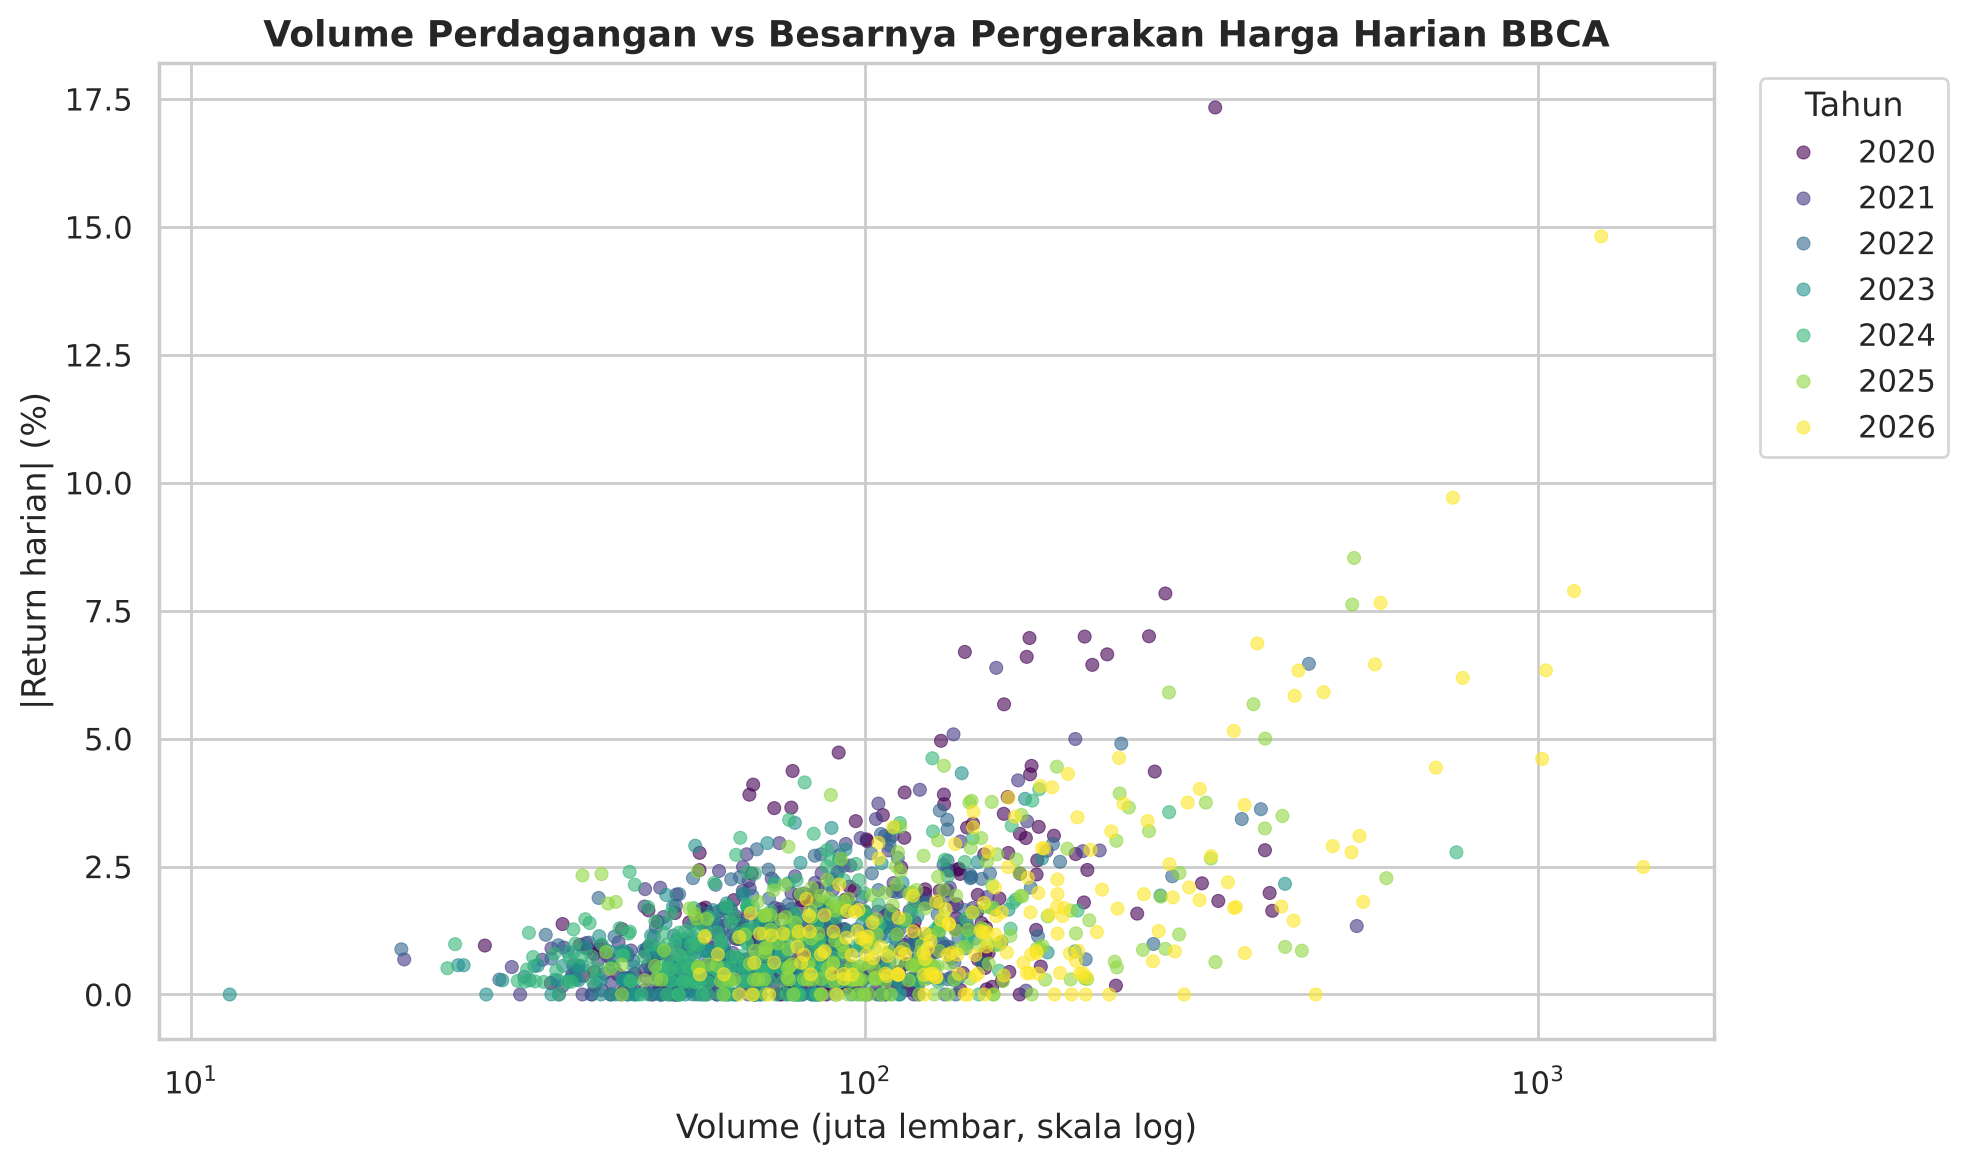

Korelasi Pearson  : 0.540
Korelasi Spearman : 0.387


,Rentang volume (juta),Rata-rata |return| (%),Jumlah hari
Volume (juta),,,
Q1 (terendah),11–57,0.67,327
Q2,57–74,0.91,326
Q3,74–94,1.05,326
Q4,94–133,1.21,326
Q5 (tertinggi),"133–1,433",2.31,327


In [12]:
data_sc = saham.dropna(subset=["Return (%)"]).assign(**{"|Return| (%)": lambda d: d["Return (%)"].abs()})
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=data_sc, x="Volume (juta)", y="|Return| (%)", hue="Tahun", palette="viridis",
                alpha=0.6, s=22, edgecolor=None, ax=ax)
ax.set_xscale("log")
ax.set_title("Volume Perdagangan vs Besarnya Pergerakan Harga Harian BBCA")
ax.set_xlabel("Volume (juta lembar, skala log)")
ax.set_ylabel("|Return harian| (%)")
ax.legend(title="Tahun", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

pearson = data_sc[["Volume (juta)", "|Return| (%)"]].corr().iloc[0, 1]
spearman = data_sc[["Volume (juta)", "|Return| (%)"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Pearson  : {pearson:.3f}")
print(f"Korelasi Spearman : {spearman:.3f}")

kuintil = pd.qcut(data_sc["Volume (juta)"], 5, labels=["Q1 (terendah)", "Q2", "Q3", "Q4", "Q5 (tertinggi)"])
tabel_vol = data_sc.groupby(kuintil, observed=True).agg(
    **{"Rentang volume (juta)": ("Volume (juta)", lambda v: f"{v.min():,.0f}–{v.max():,.0f}"),
       "Rata-rata |return| (%)": ("|Return| (%)", "mean"), "Jumlah hari": ("|Return| (%)", "size")})
display(tabel_vol.round(2))

## 5.8 Visualisasi 5 — Pola return bulanan (heatmap)
Heatmap menampilkan return setiap bulan (baris = tahun, kolom = bulan). Warna hijau berarti harga naik pada bulan tersebut, merah berarti turun.

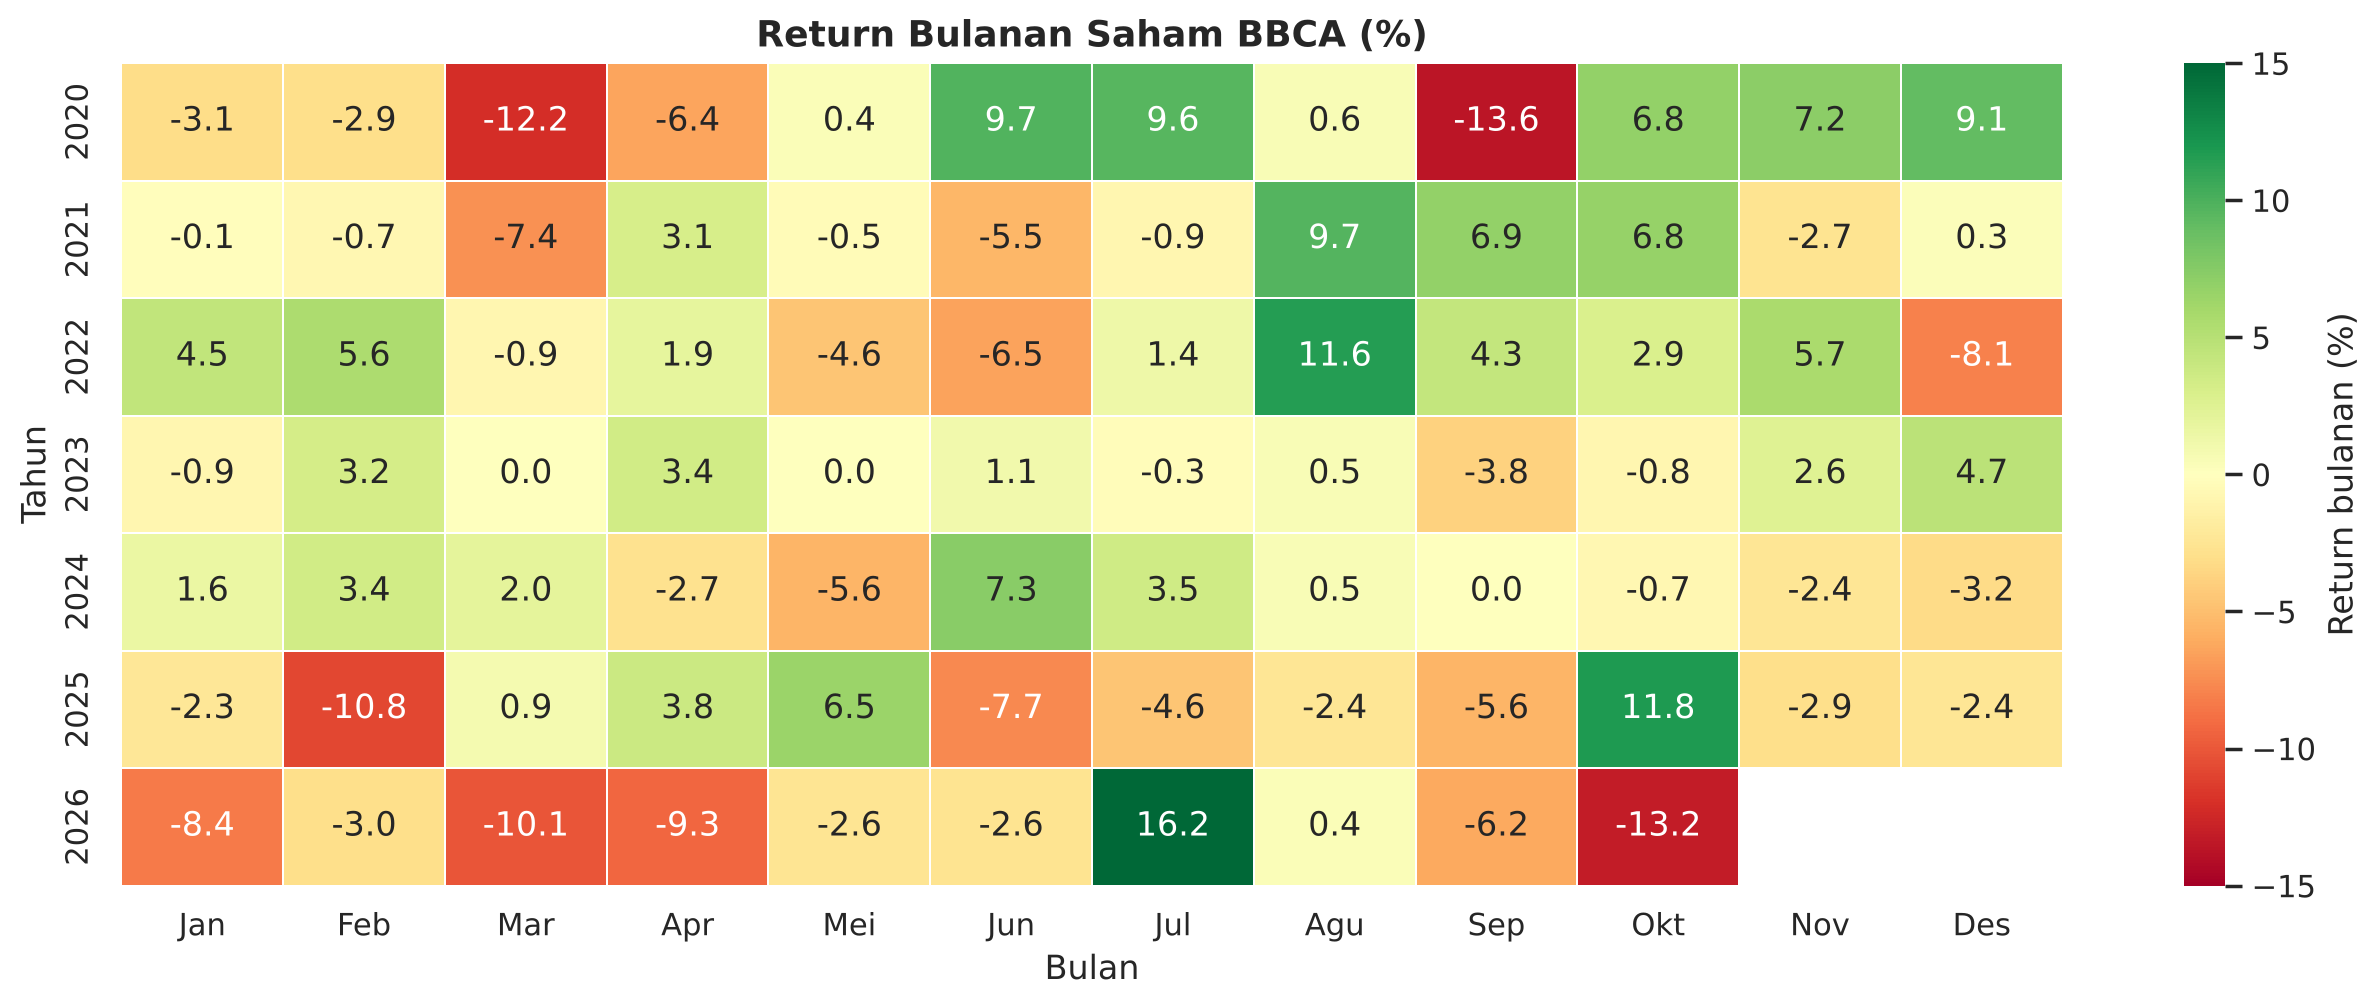

,Jan,Feb,Mar,Apr,Mei,Jun,Jul,Agu,Sep,Okt,Nov,Des
Rata-rata return (%),-1.26,-0.76,-3.95,-0.9,-0.91,-0.59,3.56,2.98,-2.58,1.94,1.23,0.08
Tahun naik,2.00,3.00,2.00,4.0,2.00,3.00,4.00,6.00,2.00,4.00,3.00,3.00
Tahun tersedia,7.00,7.00,7.00,7.0,7.00,7.00,7.00,7.00,7.00,7.00,6.00,6.00


Rata-rata bulan terbaik: Jul (+3.56%) | terburuk: Mar (-3.95%)
Return bulan terbesar : Jul 2026 (+16.2%) | terkecil: Sep 2020 (-13.6%)


In [13]:
close_bulanan = saham["Close"].resample("ME").last()
ret_bulanan = close_bulanan.pct_change() * 100
ret_bulanan.iloc[0] = (close_bulanan.iloc[0] / saham["Close"].iloc[0] - 1) * 100
nama_bln = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
pivot = (ret_bulanan.to_frame("r").assign(Tahun=lambda d: d.index.year, Bulan=lambda d: d.index.month)
         .pivot(index="Tahun", columns="Bulan", values="r").reindex(columns=range(1, 13)))
pivot.columns = nama_bln

fig, ax = plt.subplots(figsize=(13, 5.2))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="RdYlGn", center=0, vmin=-15, vmax=15,
            linewidths=0.6, cbar_kws={"label": "Return bulanan (%)"}, ax=ax)
ax.set_title("Return Bulanan Saham BBCA (%)")
ax.grid(False)
ax.set_xlabel("Bulan")
ax.set_ylabel("Tahun")
plt.tight_layout()
plt.show()

rata_bulan = pivot.mean().round(2)
naik_bulan = (pivot > 0).sum()
display(pd.DataFrame({"Rata-rata return (%)": rata_bulan, "Tahun naik": naik_bulan, "Tahun tersedia": pivot.notna().sum()}).T)
print(f"Rata-rata bulan terbaik: {rata_bulan.idxmax()} ({rata_bulan.max():+.2f}%) | terburuk: {rata_bulan.idxmin()} ({rata_bulan.min():+.2f}%)")
print(f"Return bulan terbesar : {ret_bulanan.idxmax():%b %Y} ({ret_bulanan.max():+.1f}%) | terkecil: {ret_bulanan.idxmin():%b %Y} ({ret_bulanan.min():+.1f}%)")

## 5.9 Ringkasan temuan dan rekomendasi
Rekomendasi berikut adalah implikasi dari analisis deskriptif data historis, **bukan saran investasi**, dan tidak dapat memprediksi harga di masa depan.

In [14]:
ret_total = (saham["Close"].iloc[-1] / saham["Close"].iloc[0] - 1) * 100
tahun_berjalan = (saham.index[-1] - saham.index[0]).days / 365.25
cagr = ((saham["Close"].iloc[-1] / saham["Close"].iloc[0]) ** (1 / tahun_berjalan) - 1) * 100
puncak = saham["Close"].idxmax()

print("RINGKASAN DATA SAHAM BBCA")
print(f"- Periode            : {saham.index.min():%d %b %Y} – {saham.index.max():%d %b %Y} ({len(saham):,} hari bursa)")
print(f"- Return total       : {ret_total:+.1f}%  (rata-rata per tahun/CAGR {cagr:+.1f}%)")
print(f"- Puncak harga       : Rp{saham['Close'].max():,.0f} pada {puncak:%d %b %Y}")
print(f"- Drawdown terdalam  : {saham['Drawdown (%)'].min():.1f}% ({saham['Drawdown (%)'].idxmin():%d %b %Y})")
print(f"- Volatilitas tahunan: {r.std() * np.sqrt(252):.1f}%")
print(f"- Tahun terbaik/terburuk: {terbaik} ({ringkas_tahun.loc[terbaik,'Return (%)']:+.1f}%) / {terburuk} ({ringkas_tahun.loc[terburuk,'Return (%)']:+.1f}%)")
print(f"- Korelasi volume vs |return|: Pearson {pearson:.2f}, Spearman {spearman:.2f}")

RINGKASAN DATA SAHAM BBCA
- Periode            : 02 Jan 2020 – 28 Oct 2026 (1,633 hari bursa)
- Return total       : -21.2%  (rata-rata per tahun/CAGR -3.4%)
- Puncak harga       : Rp10,950 pada 23 Sep 2024
- Drawdown terdalam  : -56.0% (19 Oct 2026)
- Volatilitas tahunan: 28.6%
- Tahun terbaik/terburuk: 2022 (+17.1%) / 2026 (-34.7%)
- Korelasi volume vs |return|: Pearson 0.54, Spearman 0.39


## 5.10 Simpan ringkasan ke Excel
Tabel ringkasan tahunan, data bulanan, dan data harian beserta variabel turunannya disimpan ke satu file Excel sebagai lampiran.

In [15]:
file_xlsx = Path("Ringkasan_Analisis_Saham_BBCA.xlsx")
with pd.ExcelWriter(file_xlsx, engine="openpyxl") as w:
    ringkas_tahun.round(2).to_excel(w, sheet_name="Ringkasan_Tahunan")
    pivot.round(2).to_excel(w, sheet_name="Return_Bulanan")
    saham.round(4).to_excel(w, sheet_name="Data_Harian")
print("Tersimpan:", file_xlsx.resolve())

Tersimpan: /home/claude/uts/run/Ringkasan_Analisis_Saham_BBCA.xlsx
